# Chart 3: U.S. labor force participation rate, ages 25 to 54

Article: <https://www.dailysignal.com/2026/09/30/real-story-gas-prices/> (Sanjai Bhagat, The Daily Signal, 30 Sep 2026).

Replicates the article's third chart: the monthly, seasonally adjusted participation rate of 25- to 54-year-olds from January 1980 to the latest release. Cited source: Federal Reserve Bank of St. Louis (FRED), series `LNS11300060`, which republishes the BLS Current Population Survey. If FRED is unreachable the fetcher falls back to the BLS API; the values are identical.

Shared pieces live in two modules: `fetch_data.py` checks whether the local data is current and downloads it if not;
`charts.py` holds the styling, the administration windows and the chart helpers. The rendered PNG is written to `output/`.

## Data currency check

Only the sources this chart needs are checked. Stale or missing copies are downloaded; current ones are left alone.

In [1]:
import fetch_data

statuses = fetch_data.refresh(['lfpr_25_54'])

lfpr_25_54     current    latest=2026-09-01 fetched=2026-10-06T20:52:43+00:00


## Load the data

In [2]:
import polars as pl
import charts

lfpr = fetch_data.load("lfpr_25_54").filter(pl.col("lfpr_25_54_pct").is_not_null())  # date, lfpr_25_54_pct, note
print(f"{lfpr['date'].min()} .. {lfpr['date'].max()}  ({lfpr.height} months)")
lfpr.tail(3)

1980-01-01 .. 2026-09-01  (560 months)


date,lfpr_25_54_pct,note
date,f64,str
2026-07-01,83.4,null
2026-08-01,83.4,null
2026-09-01,83.7,null


## Chart

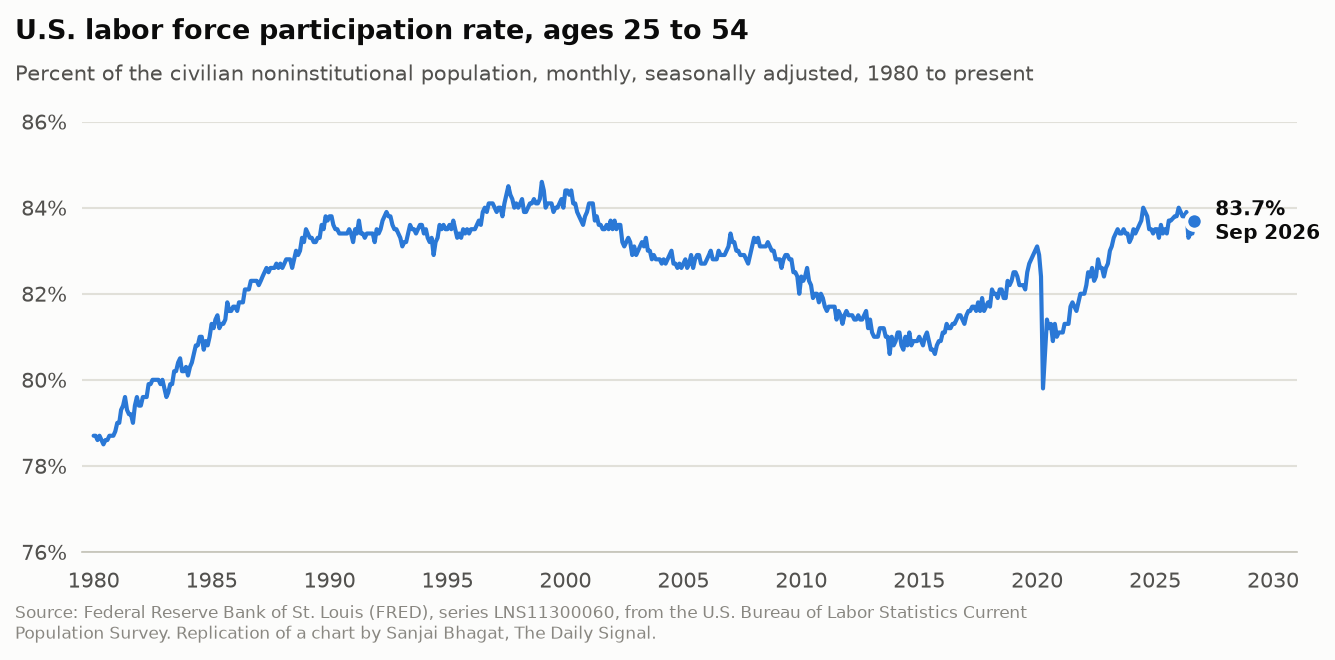

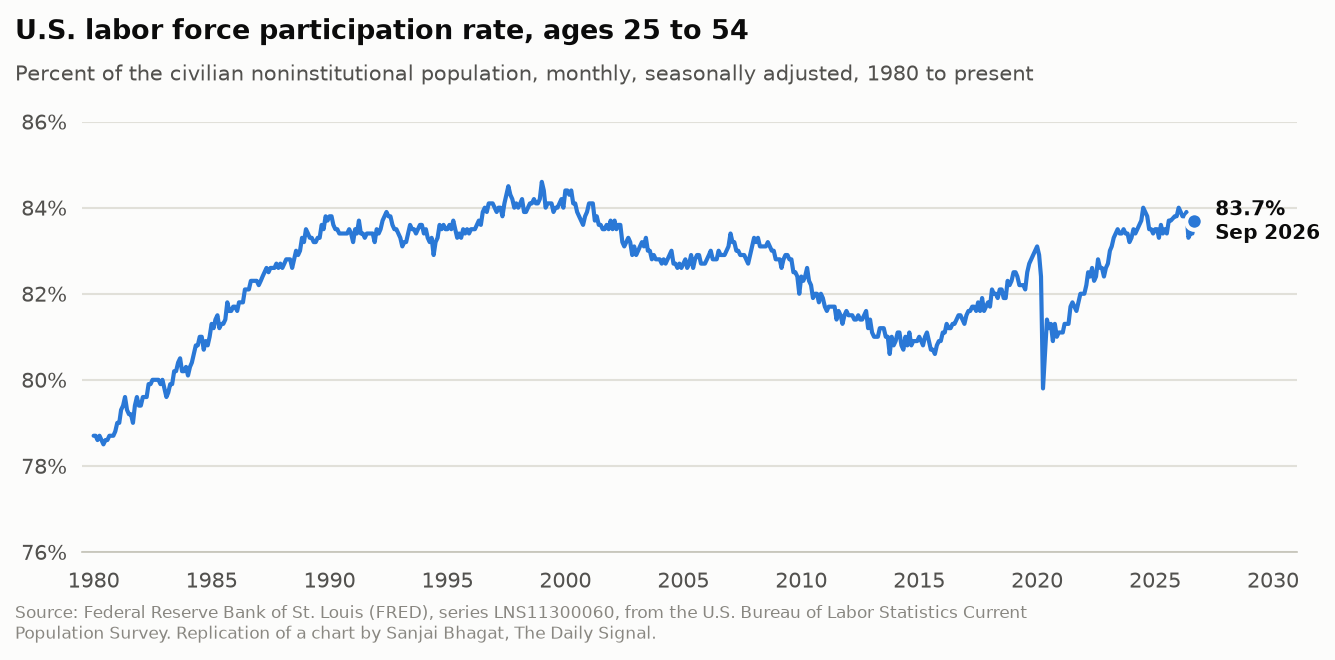

In [3]:
last = lfpr.row(-1, named=True)

charts.line_chart(
    lfpr["date"].to_numpy(), lfpr["lfpr_25_54_pct"].to_numpy(),
    title="U.S. labor force participation rate, ages 25 to 54",
    subtitle="Percent of the civilian noninstitutional population, monthly, seasonally adjusted, 1980 to present",
    source="Source: Federal Reserve Bank of St. Louis (FRED), series LNS11300060, from the U.S. Bureau of Labor Statistics Current Population Survey. Replication of a chart by Sanjai Bhagat, The Daily Signal.",
    ylim=(76, 86), ystep=2, yfmt=lambda v: f"{v:.0f}%",
    end_label=f"{last['lfpr_25_54_pct']:.1f}%\n{last['date'].strftime('%b %Y')}",
    fname="03_lfpr_25_54.png",
)

## Notes

Same series and span as the article; newer months are appended as BLS releases them. The original chart's x-axis showed
FRED's `YYYY-MM-DD` download labels; this version labels every fifth year.